# Spotify Tracks · Evaluación Parcial 3

**MLY1101 · Caso C · Benjamín Palomino y Benjamín Díaz**

El equipo de curaduría necesita decidir qué canciones revisar primero cuando el tiempo es limitado. Estimamos la popularidad **observada** en escala 0–100 y exploramos perfiles acústicos. No hay fechas para prometer predicción futura. Seguir el [informe técnico](../docs/ep3/informe_tecnico.md) para criterios, decisiones y limitaciones.

El modo normal recalcula el flujo completo desde el CSV. La variable opcional `SPOTIFY_EP3_REUSE=1` permite inspeccionar un ajuste ya medido y ejecutar las demás etapas de nuevo. El cuaderno identifica claramente el modo usado.

In [1]:
from pathlib import Path
import sys, os, json, time
import pandas as pd
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/eva3/run.py').is_file())
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'reports/eva3'
from src.eva3.data import prepare
from src.eva3.run import train_supervised, finish_run
reuse = os.environ.get('SPOTIFY_EP3_REUSE') == '1'
start = time.perf_counter()
print('Modo:', 'inspección de ajuste medido' if reuse else 'reentrenamiento completo')

Modo: reentrenamiento completo


## 1. Comprensión, preparación y EDA

Se verifica el CSV original, se conserva el criterio de etiquetas de EP2 y se documentan los descartes. Los componentes conectan audio idéntico y posibles versiones con el mismo artista principal y título normalizado. Una familia queda en una sola partición; la reserva es nueva para el protocolo EP3, pero usa el mismo origen histórico.

In [2]:
def evidence(name):
    return json.loads((OUT / name).read_text(encoding='utf-8'))

data = prepare(ROOT, OUT)
assert not any(data['audit'][name] for name in
               ['shared_tracks', 'shared_groups', 'shared_audio_groups', 'shared_recording_keys'])
display(pd.Series(data['audit'], name='auditoría').to_frame())
display(pd.read_csv(OUT / 'cleaning.csv'))
display(pd.read_csv(OUT / 'target_bands.csv'))

,auditoría
raw_sha256,335e5ee0a07a3f30b20ca9860c87562c98082a032e0ecd...
normalized_sha256,b202fa49909b2d5cef71a04b1d21243cfeb36414535f2c...
raw_bytes,20232245
raw_crlf_count,114001
raw_lf_count,0
archive_member,Spotify_Dataset/Spotify_Tracks_Dataset.csv
archive_member_sha256,b202fa49909b2d5cef71a04b1d21243cfeb36414535f2c...
provided_zip_sha256,40cd5ca85461ed70d00810bfbbe2395e37109d533ea683...
matches_received_csv_after_newline_normalization,True
exact_bytes_match_received_csv,False


,paso,filas_antes,filas_despues,filas_eliminadas
0,Eliminar columna de indice exportado,114000,114000,0
1,"Eliminar registros sin artista, album o cancion",114000,113999,1
2,Conservar un registro por track_id,113999,89740,24259
3,Conservar duraciones entre 30 segundos y 20 mi...,89740,89653,87
4,Eliminar tempo o compas no validos,89653,89495,158
5,Validar caracteristicas de audio entre 0 y 1,89495,89495,0


,split,target_band,rows,share_pct
0,test,0-20,5003,27.929437
1,test,21-40,5957,33.255178
2,test,41-60,5146,28.727740
3,test,61-80,1698,9.479149
4,test,81-100,109,0.608497
5,train,0-20,20042,27.998659
6,train,21-40,23931,33.431589
7,train,41-60,20586,28.758626
8,train,61-80,6633,9.266296
9,train,81-100,390,0.544830


## 2. Optimización y ensambles

El MAE agrupado de desarrollo ordena modelos y configuraciones. Las transformaciones que usan popularidad histórica se reconstruyen dentro de cada fold; una canción no aporta su objetivo a su propio predictor. Se compara el boosting de referencia con su versión ajustada, la agregación de árboles con un árbol y la combinación de predictores con sus componentes.

In [3]:
decision = train_supervised(data, ROOT, reuse=reuse)
assert decision['test_used_for_selection'] is False
display({name: decision[name] for name in ['selected_model', 'criterion', 'best_params', 'blend_weights']})
display(pd.read_csv(OUT / 'cv_summary.csv'))
display(pd.read_csv(OUT / 'search_summary.csv'))

EP3 fold 1/5: 57,304 ajuste, 14,278 validación


  hgb_metadatos_ajustado: 8 configuraciones


  extra_trees_metadatos: 3 configuraciones


  ridge_metadatos: 3 configuraciones


  calibrar pesos solo dentro de entrenamiento externo


EP3 fold 2/5: 57,286 ajuste, 14,296 validación


... (20 outputs left out)

                 model    cv_mae       mae      rmse        r2  within_15  within_20
hgb_metadatos_ajustado  5.129028  5.020411  8.500935  0.829774   0.919723   0.951655
      mezcla_calibrada  5.376844  5.219131  8.210101  0.841223   0.926534   0.961480
 extra_trees_metadatos  5.400212  5.251223  8.268217  0.838967   0.924133   0.960420
    hgb_metadatos_base  5.482764  5.277837  8.285236  0.838303   0.926478   0.960085
       mezcla_uniforme  5.813934  5.574739  8.478123  0.830687   0.921900   0.957573
       arbol_metadatos  7.100476  6.941542 10.826467  0.723901   0.863339   0.921063
       ridge_metadatos  7.671148  7.177697 10.450226  0.742757   0.865796   0.928320
               hgb_ep2 11.442343 11.380983 16.367721  0.368944   0.731257   0.816111
         dummy_mediana 17.244438 17.266455 20.606719 -0.000251   0.526824   0.633786


{'selected_model': 'hgb_metadatos_ajustado',
 'criterion': 'menor MAE medio en cinco folds agrupados del entrenamiento; empate por nombre',
 'best_params': {'hgb_metadatos_ajustado': {'l2_regularization': 2.0,
   'learning_rate': 0.07,
   'loss': 'absolute_error',
   'max_iter': 340,
   'max_leaf_nodes': 63,
   'min_samples_leaf': 14},
  'extra_trees_metadatos': {'max_features': 0.85,
   'max_samples': 0.9,
   'min_samples_leaf': 3,
   'n_estimators': 100},
  'ridge_metadatos': {'alpha': 2.0}},
 'blend_weights': {'mezcla_uniforme': {'hgb_metadatos_ajustado': 0.3333333333333333,
   'extra_trees_metadatos': 0.3333333333333333,
   'ridge_metadatos': 0.3333333333333333},
  'mezcla_calibrada': {'hgb_metadatos_base': 0.4,
   'extra_trees_fijo': 0.6,
   'ridge_fijo': 0.0}}}

,model,cv_std,cv_oof_mae,cv_mae,cv_mse,cv_rmse,cv_r2,cv_within_5,cv_within_10,cv_within_15,cv_within_20
0,hgb_metadatos_ajustado,0.043300,5.129063,5.129028,74.223197,8.614569,0.824884,0.694091,0.853580,0.915007,0.948618
1,mezcla_calibrada,0.049472,5.376924,5.376844,69.307927,8.324616,0.836467,0.642121,0.846165,0.922424,0.959193
2,extra_trees_metadatos,0.045997,5.400232,5.400212,70.371519,8.388166,0.833964,0.641596,0.844294,0.921086,0.958593
3,hgb_metadatos_base,0.081213,5.483000,5.482764,70.616635,8.402934,0.833367,0.629230,0.843471,0.922382,0.959026
4,mezcla_uniforme,0.051049,5.814030,5.813934,74.700885,8.642433,0.823754,0.608205,0.833663,0.916685,0.955059
5,arbol_metadatos,0.114432,7.100275,7.100476,123.226999,11.098526,0.709306,0.569600,0.763287,0.858789,0.913410
6,ridge_metadatos,0.090817,7.671380,7.671148,122.673665,11.074209,0.710603,0.508114,0.728006,0.844604,0.913872
7,hgb_ep2,0.098665,11.442506,11.442343,271.435469,16.474937,0.359540,0.388524,0.613387,0.733070,0.813772
8,dummy_mediana,0.124543,17.244531,17.244438,423.954134,20.589727,-0.000297,0.158391,0.336633,0.525316,0.636461


,model,trial,params,cv_mae,cv_std,cv_rmse,cv_r2,cv_within_15,seconds,selected_in_family
0,extra_trees_metadatos,2,"{""max_features"": 0.85, ""max_samples"": 0.9, ""mi...",5.400212,0.045997,8.388166,0.833964,0.921086,14.684547,True
1,extra_trees_metadatos,1,"{""max_features"": 0.8, ""max_samples"": 0.85, ""mi...",5.412487,0.048989,8.412811,0.832988,0.920261,11.360282,False
2,extra_trees_metadatos,3,"{""max_features"": 0.65, ""max_samples"": 0.85, ""m...",5.482047,0.051451,8.491334,0.829859,0.917885,8.171427,False
3,hgb_metadatos_ajustado,6,"{""l2_regularization"": 2.0, ""learning_rate"": 0....",5.129028,0.043300,8.614569,0.824884,0.915007,10.674156,True
4,hgb_metadatos_ajustado,8,"{""l2_regularization"": 0.5, ""learning_rate"": 0....",5.130076,0.046824,8.618555,0.824713,0.915634,12.694767,False
5,hgb_metadatos_ajustado,7,"{""l2_regularization"": 6.0, ""learning_rate"": 0....",5.175257,0.042310,8.654381,0.823265,0.914346,10.208349,False
6,hgb_metadatos_ajustado,5,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",5.264611,0.050038,8.758080,0.819004,0.911497,4.999014,False
7,hgb_metadatos_ajustado,2,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",5.409798,0.090928,8.330487,0.836227,0.923850,6.872238,False
8,hgb_metadatos_ajustado,3,"{""l2_regularization"": 2.0, ""learning_rate"": 0....",5.436881,0.145455,8.361798,0.834964,0.922830,9.415493,False
9,hgb_metadatos_ajustado,4,"{""l2_regularization"": 8.0, ""learning_rate"": 0....",5.453208,0.117808,8.372957,0.834532,0.923502,6.923271,False


## 3. Generalización y umbral del 80%

La reserva no decide el modelo. MAE y RMSE miden puntos; R² no equivale a aciertos. Además se informa la fracción de predicciones a ±5/10/15/20 puntos, con ±15 como referencia operativa propuesta. El 80% solo puede interpretarse a partir de una métrica definida. Re-muestrear familias completas estima incertidumbre de la reserva, no resultados futuros.

K-Means K=1: silhouette=None


K-Means K=2: silhouette=0.24330336238994177


K-Means K=3: silhouette=0.15356567389287587


K-Means K=4: silhouette=0.15985098432554345

K-Means K=5: silhouette=0.1619186573040514


K-Means K=6: silhouette=0.16785692779522293


... (4 outputs left out)

,model,cv_std,cv_oof_mae,cv_mae,cv_mse,cv_rmse,cv_r2,cv_within_5,cv_within_10,cv_within_15,cv_within_20,mae,mse,rmse,r2,within_5,within_10,within_15,within_20
0,hgb_metadatos_ajustado,0.043300,5.129063,5.129028,74.223197,8.614569,0.824884,0.694091,0.853580,0.915007,0.948618,5.020411,72.265898,8.500935,0.829774,0.700999,0.861274,0.919723,0.951655
1,mezcla_calibrada,0.049472,5.376924,5.376844,69.307927,8.324616,0.836467,0.642121,0.846165,0.922424,0.959193,5.219131,67.405751,8.210101,0.841223,0.659633,0.855077,0.926534,0.961480
2,extra_trees_metadatos,0.045997,5.400232,5.400212,70.371519,8.388166,0.833964,0.641596,0.844294,0.921086,0.958593,5.251223,68.363409,8.268217,0.838967,0.656953,0.851951,0.924133,0.960420
3,hgb_metadatos_base,0.081213,5.483000,5.482764,70.616635,8.402934,0.833367,0.629230,0.843471,0.922382,0.959026,5.277837,68.645129,8.285236,0.838303,0.652599,0.853626,0.926478,0.960085
4,mezcla_uniforme,0.051049,5.814030,5.813934,74.700885,8.642433,0.823754,0.608205,0.833663,0.916685,0.955059,5.574739,71.878563,8.478123,0.830687,0.633227,0.846536,0.921900,0.957573
5,arbol_metadatos,0.114432,7.100275,7.100476,123.226999,11.098526,0.709306,0.569600,0.763287,0.858789,0.913410,6.941542,117.212378,10.826467,0.723901,0.574387,0.768381,0.863339,0.921063
6,ridge_metadatos,0.090817,7.671380,7.671148,122.673665,11.074209,0.710603,0.508114,0.728006,0.844604,0.913872,7.177697,109.207213,10.450226,0.742757,0.528945,0.753363,0.865796,0.928320
7,hgb_ep2,0.098665,11.442506,11.442343,271.435469,16.474937,0.359540,0.388524,0.613387,0.733070,0.813772,11.380983,267.902302,16.367721,0.368944,0.392285,0.615140,0.731257,0.816111
8,dummy_mediana,0.124543,17.244531,17.244438,423.954134,20.589727,-0.000297,0.158391,0.336633,0.525316,0.636461,17.266455,424.636856,20.606719,-0.000251,0.155139,0.335176,0.526824,0.633786


,contrast,candidate,reference,basis,cv_folds,cv_mae_candidate,cv_mae_reference,cv_delta_mae_points,cv_positive_folds,cv_delta_min,...,holdout_groups,holdout_mae_candidate,holdout_reference_prediction_column,holdout_status,holdout_mae_reference,holdout_delta_mae_points,holdout_relative_gain_pct,holdout_delta_ci95_low,holdout_delta_ci95_high,holdout_ci_includes_zero
0,ajuste_hgb,hgb_metadatos_ajustado,hgb_metadatos_base,Mismo boosting y predictores: variante ajustad...,5,5.129028,5.482764,0.353736,5,0.298774,...,16081,5.020411,hgb_metadatos_base,prediccion_guardada,5.277837,0.257426,4.877483,0.221294,0.293005,False
1,ensamble_arboles,extra_trees_metadatos,arbol_metadatos,ExtraTrees con configuración congelada frente ...,5,5.400212,7.100476,1.700264,5,1.542691,...,16081,5.251223,arbol_metadatos,prediccion_guardada,6.941542,1.690318,24.350761,1.602240,1.778634,False
2,mezcla_uniforme_vs_componente,mezcla_uniforme,hgb_metadatos_ajustado,Mezcla uniforme frente al componente ajustado ...,5,5.813934,5.129028,-0.684906,0,-0.735214,...,16081,5.574739,hgb_metadatos_ajustado,prediccion_guardada,5.020411,-0.554328,-11.041479,-0.604217,-0.501921,False
3,mezcla_calibrada_vs_componente,mezcla_calibrada,extra_trees_fijo,Mezcla calibrada frente al componente fijo de ...,5,5.376844,5.412487,0.035643,4,-0.000720,...,16081,5.219131,extra_trees_fijo,prediccion_guardada,5.264057,0.044926,0.853441,0.032710,0.056444,False
4,ganador_vs_ep2,hgb_metadatos_ajustado,hgb_ep2,Ganador congelado frente a la configuración de...,5,5.129028,11.442343,6.313315,5,6.253199,...,16081,5.020411,hgb_ep2,prediccion_guardada,11.380983,6.360572,55.887721,6.114871,6.609513,False


{'seed': 3103,
 'resamples': 600,
 'groups': 16081,
 'unit': 'grupo de canciones relacionadas, no fila',
 'interpretation': 'Incertidumbre de muestreo en la reserva del mismo origen, no garantía temporal.',
 'intervals': {'mae': {'point': 5.020411187981475,
   'lo_95': 4.916316962197765,
   'hi_95': 5.136316552892004},
  'within_5': {'point': 0.7009992742700831,
   'lo_95': 0.6935625884021809,
   'hi_95': 0.7075615930677674},
  'within_10': {'point': 0.8612739351309106,
   'lo_95': 0.8565429770199903,
   'hi_95': 0.8661025587662378},
  'within_15': {'point': 0.919723106124044,
   'lo_95': 0.9158222229089098,
   'hi_95': 0.9239009299258948},
  'within_20': {'point': 0.9516552224641321,
   'lo_95': 0.9482002623280041,
   'hi_95': 0.9549163099401565},
  'mae_gain_baseline': {'point': 12.246043342247967,
   'lo_95': 11.9905138790061,
   'hi_95': 12.503424309784245}}}

,dimension,group,n,mae,bias_pred_minus_real,within_15,small_sample
0,artist_seen,False,1867,7.853609,-1.150748,0.816818,False
1,artist_seen,True,16046,4.690760,-0.706153,0.931696,False
2,album_seen,False,9605,5.999176,-0.870513,0.885476,False
3,album_seen,True,8308,3.888847,-0.616045,0.959316,False
117,explicit,0,16330,5.017659,-0.743643,0.919412,False
118,explicit,1,1583,5.048800,-0.843776,0.922931,False
119,target_band,"(-1.001, 20.0]",5003,2.942509,2.092070,0.960224,False
120,target_band,"(20.0, 40.0]",5957,4.254402,0.903776,0.944603,False
121,target_band,"(40.0, 60.0]",5146,6.282984,-2.648988,0.895647,False
122,target_band,"(60.0, 80.0]",1698,9.398485,-8.321833,0.809776,False


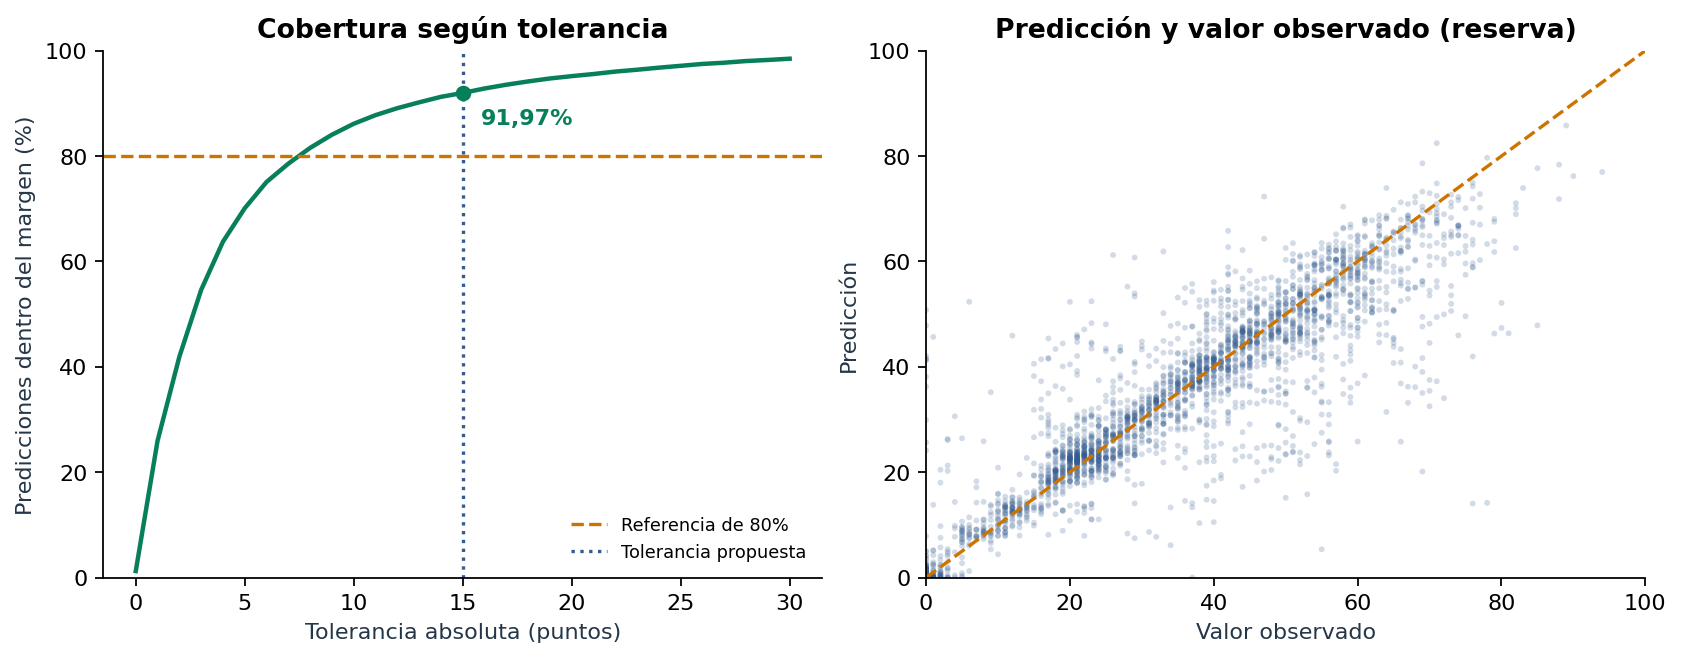

In [4]:
result = finish_run(data, ROOT, decision, refitted=not reuse, start=start)
assert result['completed']
display(pd.read_csv(OUT / 'supervised_metrics.csv'))
display(pd.read_csv(OUT / 'controlled_contrasts.csv'))
display(evidence('bootstrap.json'))
audits = pd.read_csv(OUT / 'holdout_subgroups.csv')
display(audits[audits.dimension.isin(['artist_seen', 'album_seen', 'target_band', 'explicit'])])
display(Image(filename=str(ROOT / 'images/eva3/03_reserva.png'), width=820))

## 4. Segmentación y decisión de negocio

K-Means usa diez atributos de audio escalados en desarrollo, sin popularidad ni género. El resultado propone categorías para explorar, no tipos de usuarios. La simulación supervisada compara la lista priorizada con el valor esperado de una muestra uniforme del mismo tamaño. Es una prueba retrospectiva, no un piloto real.

{'selected_k': 2,
 'elbow_chord_k': 4,
 'selection_rule': 'mayor silueta en muestra fija de 2500 train entre K=2..10 con todos los grupos >=3% de train; desempate menor K',
 'silhouette_train_sample': 0.24330336238994177,
 'silhouette_test_sample': 0.24184693201994878,
 'features': ['duration_ms',
  'danceability',
  'energy',
  'loudness',
  'speechiness',
  'acousticness',
  'instrumentalness',
  'liveness',
  'valence',
  'tempo'],
 'target_used_in_fit': False,
 'genre_used_in_fit': False,
 'pca_two_components_variance': 0.4441342472038644,
 'pca_components_for_80pct': 6,
 'stability': [{'seed': 7, 'ari_vs_42': 0.9993443685265875},
  {'seed': 2026, 'ari_vs_42': 0.997973563594929}],
 'seed': 42}

,cluster,pct_train,energy_train,acousticness_train,tempo_train,pct_test,energy_test,acousticness_test,tempo_test,uso_propuesto,delta_participacion_pp
0,0,24.983935,0.298449,0.753552,110.289349,25.361469,0.299057,0.756869,110.117933,Explorar listas de escucha tranquila,0.377535
1,1,75.016065,0.747871,0.184713,126.299447,74.638531,0.749413,0.187135,126.286656,Priorizar revisión para listas activas,-0.377535


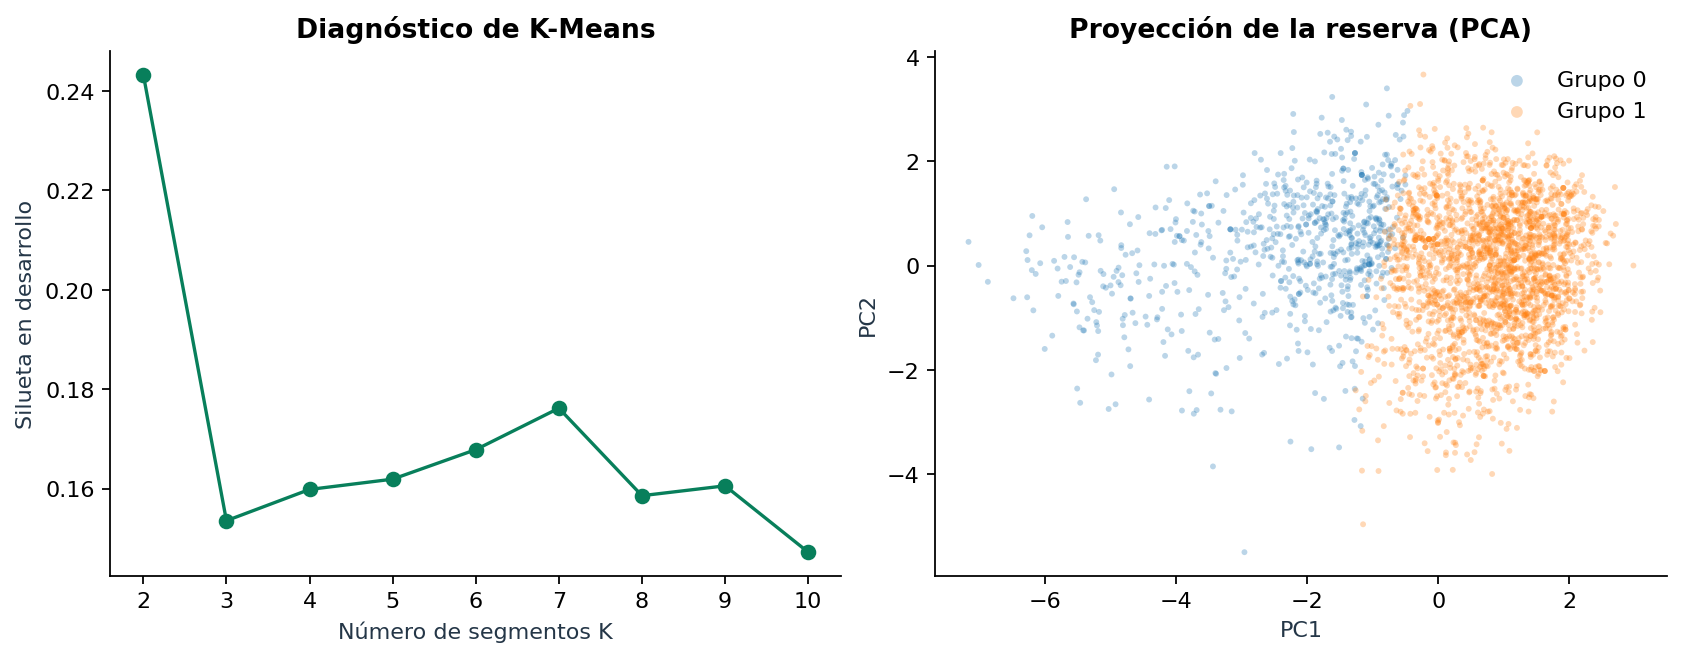

{'scope': 'Simulación retrospectiva de una lista para revisión humana; no es un piloto comercial.',
 'budget_fraction': 0.2,
 'budget_songs': 3582,
 'threshold_quantile_train': 0.75,
 'threshold_train': 49.0,
 'selected_model': {'songs': 3582,
  'hits': 3065,
  'precision_at_budget': 0.8556672250139586,
  'recall_at_budget': 0.6777974347633791,
  'mean_popularity': 58.920156337241764,
  'genres': 82,
  'genres_total_holdout': 113},
 'uniform_reference': {'precision_expected': 0.252442360296991,
  'mean_popularity_expected': 33.32669011332552,
  'explanation': 'Valor esperado de una muestra uniforme del mismo tamaño, sin ranking.'},
 'precision_gain_pp': 60.322486471696756,
 'mean_popularity_gain_points': 25.593466223916245,
 'candidate_rankings': 9}

,track_id,estimated_popularity
0,1EzrEOXmMH3G43AXT1y7pA,5.211168e+01
1,3S0OXQeoh0w6AY8WQVckRW,5.211168e+01
2,0dzKBptH2P5j5a0MifBMwM,2.662260e-11
3,3H36x7buZdQD4687VmFrwY,6.447466e-01
4,0xbMRcMFqxJq1Wa7tvWPtn,1.613431e+00


Ajuste supervisado rehecho en esta ejecución: True


In [5]:
display(evidence('clustering.json'))
display(pd.read_csv(OUT / 'segment_business_profiles.csv'))
display(Image(filename=str(ROOT / 'images/eva3/04_segmentos.png'), width=820))
display(evidence('business.json'))
display(pd.read_csv(OUT / 'prediction_example.csv'))
print('Ajuste supervisado rehecho en esta ejecución:', result['supervised_refit'])

## Figuras complementarias

La distribución del objetivo contextualiza la representatividad interna. La comparación de MAE pertenece a desarrollo: ordenar por esa figura no equivale a medir un escenario futuro.

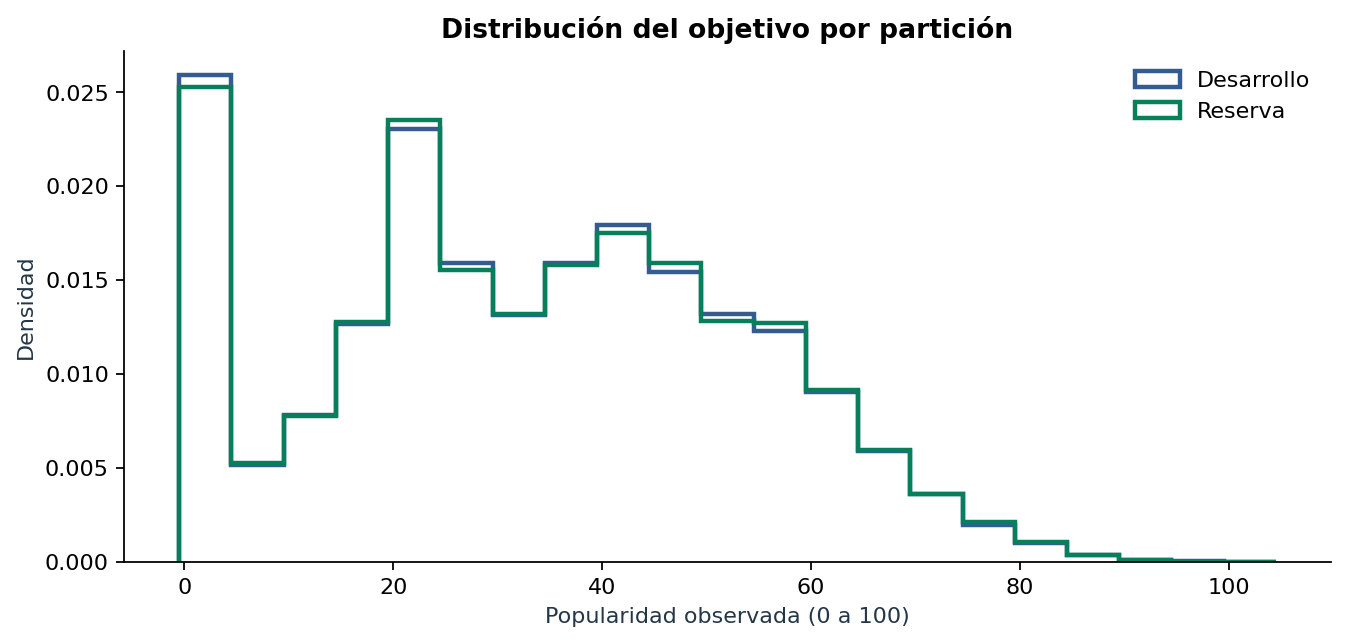

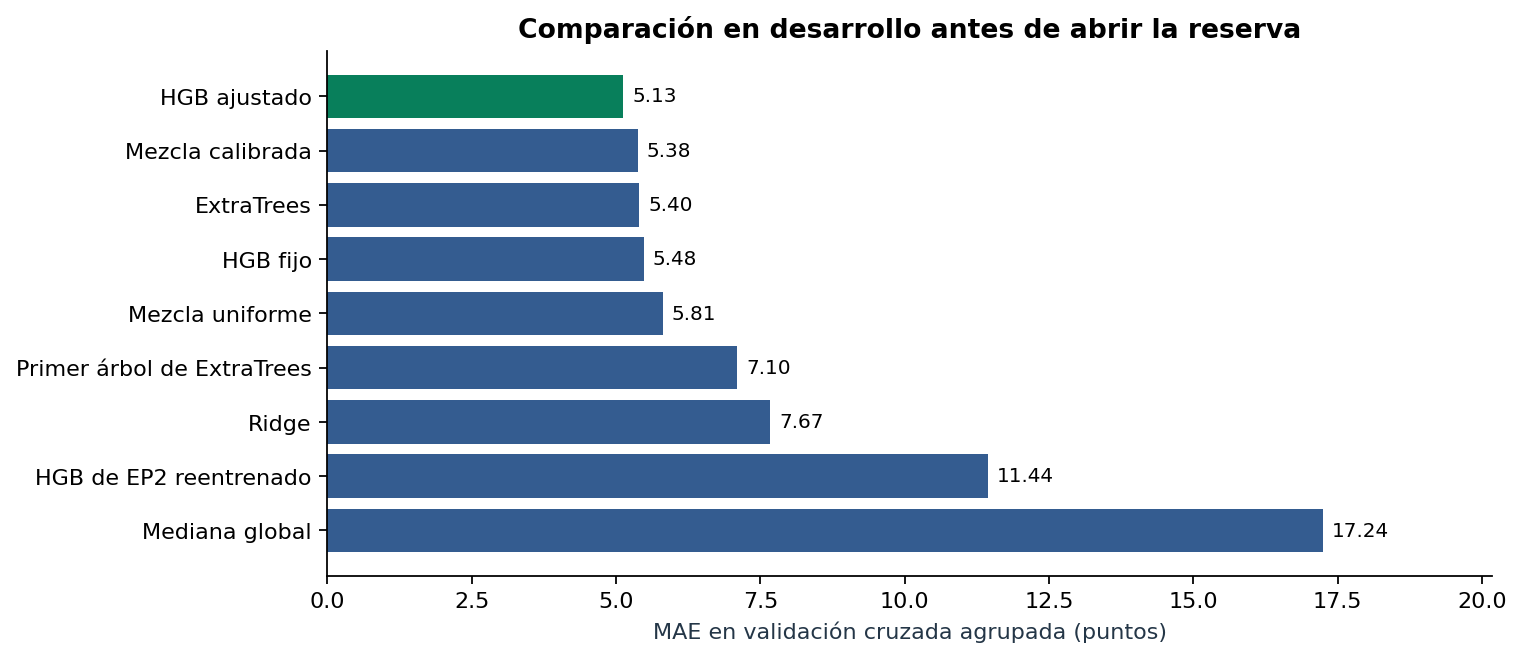

In [6]:
for figure in ['01_objetivo.png', '02_modelos_cv.png']:
    display(Image(filename=str(ROOT / 'images/eva3' / figure), width=760))

## 5. Alcance y siguientes pasos

Usar solo para apoyar revisión editorial. El histórico de artista o álbum puede favorecer catálogos conocidos; analizar por separado el desempeño en artistas no vistos y en géneros poco representados. Para decidir un uso real se requiere evaluación temporal y aprobación del margen tolerable. Consultar el [resumen ejecutivo](../docs/ep3/informe_ejecutivo.md) y el detalle del informe.